Материал от Google по линейной регресии

https://developers.google.com/machine-learning/crash-course/linear-regression?hl=ru

# Алгоритм линейной регрессии. Градиентный спуск.

## Основные понятия и обозначения<a class="anchor" id="0">

Обучение с учителем предполагает наличие обучающей выборки — множества пар
$$(𝑥_{i},𝑦_{i}),$$ где $𝑥_{i}$ — объекты, а $y_{i}$  — соответствующие им известные ответы. Выборка
$𝑋={(𝑥_{i},𝑦_{i})}^l_{i=1}
  служит основой для построения модели, которая должна улавливать устойчивую зависимость между объектами и ответами.

Моделью будем называть отображение
𝑎(𝑥) из пространства объектов в пространство ответов. Однако само по себе наличие отображения недостаточно: необходимо ввести критерий качества. Для этого задаётся функционал ошибки
𝑄(𝑎,𝑋), который по фиксированной выборке сопоставляет модели числовое значение, характеризующее её качество на этих данных.

Процедуру обучения можно трактовать как задачу оптимизации: среди некоторого класса моделей 𝐴 требуется выбрать такую модель $𝑎∈𝐴$, для которой значение функционала ошибки на обучающей выборке минимально, то есть
$$𝑄(𝑎,𝑋)→min 𝑎∈𝐴.$$

Именно выбор и последующая минимизация функционала ошибки определяют, что именно считается «хорошим» решением в конкретной постановке.

## Линейная регрессия. MSE<a class="anchor" id="1">

Линейные модели - это такие модели, которые сводятся к суммированию значений признаков с некоторыми весами. Само название модели говорит о том, что зависимость предсказываемой переменной от признаков будет линейной:

$$a(x) = w_{0}+\sum^{d}_{i=1}w_{i}x_{i}.$$

**Линейная регрессия** — модель зависимости переменной x от одной или нескольких других переменных (факторов, регрессоров, независимых переменных) с линейной функцией зависимости.

В данном случае параметрами моделей являются веса $w_{i}$. Вес $w_{0}$ называется _свободным коэффициентом_ или _сдвигом_. Оптимизация модели в таком случае заключается в подборе оптимальных значений весов. Сумму в формуле также можно описать как скалярное произведение вектора признаков $x=(x^{1},...,x^{d})$ на вектор весов $w=(w_{1},...,w_{d})$:

$$a(x) = w_{0}+\left \langle w,x \right \rangle.$$


Обратим внимание, что сдвиг делает модель неоднородной и затрудняет ее дальнейшую оптимизацию. Для устранения этого фактора обычно используют прием, позволяющий упростить запись: к признаковому описанию объекта добавляется еще один признак (константный), на каждом объекте равный единице. В этом случае вес при нем как раз будет по смыслу совпадать со свободным коэффициентом, и сам $w_{0}$ будет не нужен. Тогда получим

$$a(x) = \sum^{d+1}_{i=1}w_{i}x_{i}=\left \langle w,x \right \rangle.$$

За счет простой формы линейные модели достаточно легко обучаются и позволяют работать с зашумленными данными, небольшими выборками, контролирауя при этом риск переобучения.


|$$a(x)$$  |$$y$$    |$$a(x) - y$$ |$$|a(x) - y|$$ |$$(a(x)-y)^2$$|
|:--------:|:-------:|:-----------:|:-------------:|:------------:|
|11        |10       |1            |1              |1             |
|9         |10       |-1           |1              |1             |
|20        |10       |10           |10             |100           |
|1         |10       |-9           |9              |81            |

Для обучения модели необходимо иметь возможность измерять точность линейного алгоритма на выборке (обучающей или тестовой).

В качестве меры ошибки можно взять абсолютное отклонение истинного значения от прогноза $Q(a,y)=a(x)-y$, но тогда минимизация функционала ошибки (в которой и состоит задача обучения) будет достигаться при принятии им отрицательного значения. Например, если истинное значение ответа равно $10$, а алгоритм $a(x)$ выдает ответ $11$, отклонение будет равно $1$, а при значении предсказания равном $1$, отклонение будет равно $1-10=-9$. Значение ошибки во втором случае ниже, однако разница истинного значения и предсказания нашей модели больше. Таким образом, такой функционал ошибки не поддается минимизации.

Логичным кажется решение использовать в качестве функционала ошибки модуль отклонения $Q(a,y)=|a(x)-y|$. Соответствующий функционал ошибки называется средним абсолютным отклонением (mean absolute error, MAE):

$$Q(a,x) = \frac{1}{l}\sum^{l}_{i=1}|a(x_{i})-y_{i}|.$$

Однако, как мы далее увидим, зачастую методы оптимизации включают в себя дифференцирование, а функция модуля не является гладкой - она не имеет производной в нуле, поэтому ее оптимизация бывает затруднительной.

Поэтому сейчас основной способ измерить отклонение - посчитать квадрат разности $Q(a,y)=(a(x)-y)^{2}$. Такая функция является гладкой и имеет производную в каждой точке, а ее минимум достигается при равенстве истинного ответа $y$ и прогноза $a(x)$.

Основанный на этой функции функционал ошибки называется _среднеквадратичным отклонением_ (mean squared error, MSE):

$$Q(a,x) = \frac{1}{l}\sum^{l}_{i=1}(a(x_{i})-y_{i})^{2}.$$

## Метод наименьших квадратов<a class="anchor" id="2">

In [ ]:
y=w0+w1*x

Как уже говорилось ранее, обучение модели регрессии заключается в минимизации функционала ошибки. Таким образом, в случае использования среднеквадратичной ошибки получаем задачу оптимизации

$$Q(w,x) = \frac{1}{l}\sum^{l}_{i=1}(\left \langle w,x_{i} \right \rangle-y_{i})^{2} \rightarrow \underset{w}{\text{min}}.$$

Способ вычисления весов путем минимизации среднеквадратичного отклонения называется **методом наименьших квадратов**.


Помня, что $w$ - вектор параметров, переписанная в матричном виде задача будет выглядеть следующим образом:

$$Q(w, X) = \frac{1}{l}||Xw-y||^{2}\rightarrow \underset{w}{\text{min}},$$

где используется евклидова ($L_{2}$) норма:

$$||x|| = \sqrt{\sum_{i=1}^l{x_i^2}} $$

$$||Xw-y|| = \sqrt{\sum_{i=1}^l{(X_iw-y_i)^2}} $$

$$Q(w, X) = \frac{1}{l}\sqrt{\sum_{i=1}^l{(X_iw-y_i)^2}} ^{2} = \frac{1}{l}\sum_{i=1}^l{(X_iw-y_i)^2}$$


Продифференцировав данную функцию по вектору $w$ и приравняв к нулю, можно получить явную анатилическую формулу для решения задачи минимизации на подробный вывод аналитической формулы решения уравнения линейной регрессии):

$$w = (X^{T}X)^{-1}X^{T}y.$$

Это решение называется _нормальным уравнением_ линейной регрессии.

Более удобным подходом будет разработка решения с помощью численных методов оптимизации, одним из которых является _градиентный спуск_.

## Градиентный спуск<a class="anchor" id="3">

Среднеквадратичная ошибка имеет один минимум и непрерывна на всей области значений (то есть является выпуклой и гладкой), а значит в каждой ее точке можно посчитать частные производные.

Вспомним, что _градиентом_ функции $f$ называется $n$-мерный вектор из частных производных.

$$ \nabla f(x_{1},...,x_{d}) = \left(\frac{\partial f}{\partial x_{i}}\right)^{d}_{i=1}.$$

При этом известно, что __градиент задает направление наискорейшего роста функции__. Значит, антиградиент будет показывать направление ее скорейшего убывания, что будет полезно нам в нашей задаче минимизации функционала ошибки.

**Градиентный спуск** — метод нахождения локального экстремума функции (минимума или максимума) с помощью движения вдоль градиента.

In [ ]:
df(x1, x2, x3) = (df(x1), df(x2), df(x3))

Для решения задачи нам требуется определить некоторую стартовую точку и итерационно сдвигаться от нее в сторону антиградиента с определенным _шагом_ $\eta_{k}$, на каждом шагу пересчитывая градиент в точке, в которой мы находимся. Таким образом, имея начальный вектор весов $w^{0}$, $k$-й шаг градиентного спуска будет иметь вид

$$w^{k} = w^{k-1} - \eta_{k}\nabla Q(w^{k-1}, X).$$


Итерации следует продолжать, пока не наступает сходимость. Она определяется разными способами, но в даннном случае удобно определять как ситуацию, когда векторы весов от шага к шагу изменяются незначительно, то есть норма отклонения вектора весов на текущем шаге от предыдущего не привышает заданное значение $\varepsilon$:

$$||w^{k}-w^{k-1}|| < \varepsilon.$$

Начальный вектор весов $w_{0}$ также можно определять различными способами, обычно его берут нулевым или состоящим из случайных небольших чисел.

В случае многомерной регрессии (при количестве признаков больше 1) при оптимизации функционала ошибки

$$Q(w, X) = \frac{1}{l}||Xw-y||^{2}\rightarrow \underset{w}{\text{min}}$$

формула вычисления градиента принимает вид

$$\nabla_{w}Q(w,X) = \frac{2}{l}X^{T}(Xw-y).$$

In [ ]:
1. w0 = 0
2. k = 1:
        w1 = w0 - grad(w0)

1. Инициализация w

2. Цикл по k = 1,2,3,...:

    * $$w^{k} = w^{k-1} - \eta_{k}\nabla Q(w^{k-1}, X)$$

    * если
   $$||w^{k}-w^{k-1}|| < \varepsilon.$$
    завершить.

## <center>Практическая часть<a class="anchor" id="practice"></a><center>

Смоделируем работу градиентного спуска при помощи Numpy.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.axes3d import Axes3D

In [ ]:
np.random.seed(1234)
# Возьмем 2 признака и 1000 объектов
n_features = 2
n_objects = 1000

# сгенерируем вектор истинных весов
w_true = np.random.normal(size=(n_features))

# сгенерируем матрицу X, вычислим Y с добавлением случайного шума
X = np.random.uniform(-7, 7, (n_objects, n_features))
Y = X.dot(w_true) + np.random.normal(0, 0.5, size=(n_objects))

# возьмем нулевые начальные веса
w = np.zeros(n_features)

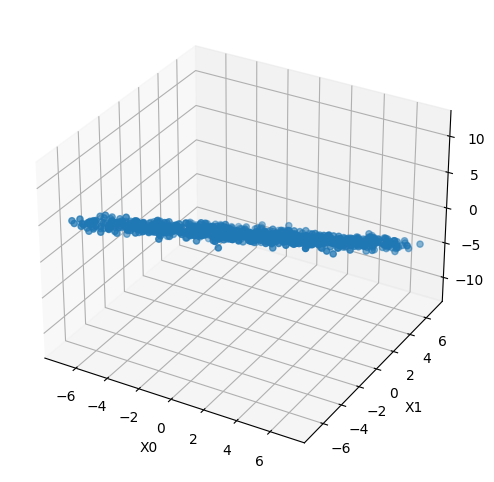

In [ ]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X[:, 0], X[:, 1], Y)

ax.set_xlabel('X0')
ax.set_ylabel('X1')
ax.set_zlabel('Y')
plt.show()

In [ ]:
# реализуем функцию, определяющую среднеквадратичную ошибку
def mserror(X, w, y):
    y_pred = X.dot(w)
    return (np.sum((y_pred - y)**2)) / len(y)

Реализуем функцию, вычисляющую вектор весов по нормальному уравнению линейной регрессии, и применим ее.
$$w = (X^{T}X)^{-1}X^{T}y.$$


In [ ]:
normal_eq_w = np.linalg.inv(np.dot(X.T, X)) @ X.T @ Y
print(f'Веса {normal_eq_w}')
print(f'В случае использования нормального уравнения функционал ошибки составляет ', end='')
print(f'{round(mserror(X, normal_eq_w, Y), 4)}')

Веса [ 0.46622325 -1.18317886]
В случае использования нормального уравнения функционал ошибки составляет 0.2413


In [ ]:
w_true

array([ 0.47143516, -1.19097569])

Обучим линейную регрессию путем градиентного спуска и получим графики изменения весов и ошибки

In [ ]:
w

array([0., 0.])

In [ ]:
# возьмем нулевые начальные веса
w = np.zeros(n_features)

# список векторов весов после каждой итерации
w_list = [w.copy()]

# список значений ошибок после каждой итерации
errors = []

# шаг градиентного спуска
eta = 0.01

# максимальное число итераций
max_iter = 1e4

# критерий сходимости (разница весов, при которой алгоритм останавливается)
min_weight_dist = 1e-8

# зададим начальную разницу весов большим числом
weight_dist = np.inf

# счетчик итераций
iter_num = 0

# ход градиентного спуска
while weight_dist > min_weight_dist and iter_num < max_iter:
    y_pred = np.dot(X, w)
    dQ = 2 / Y.shape[0] * np.dot(X.T, y_pred - Y)
    new_w = w - eta * dQ
    #вычисление евклидова расстояния между двумя векторами new_w и w с использованием нормы L2
    weight_dist = np.linalg.norm(new_w - w, ord=2)
    error = mserror(X, new_w, Y)

    w_list.append(new_w.copy())
    errors.append(error)

    print(f'Iter {iter_num}: error - {error}, weights: {new_w}')

    iter_num += 1
    w = new_w

w_list = np.array(w_list)
w_pred = w_list[-1]

print(f'В случае использования градиентного спуска функционал ошибки составляет {round(errors[-1], 4)}')

Iter 0: error - 12.198224910563502, weights: [ 0.13477638 -0.38857461]
Iter 1: error - 5.721927562708121, weights: [ 0.23166602 -0.64911175]
Iter 2: error - 2.757139097172467, weights: [ 0.30088498 -0.82395109]
Iter 3: error - 1.3976931456804218, weights: [ 0.350075   -0.94137792]
Iter 4: error - 0.7734530790003209, weights: [ 0.38487408 -1.02030733]
Iter 5: error - 0.4864474154164298, weights: [ 0.40939674 -1.07340045]
Iter 6: error - 0.35434423154423644, weights: [ 0.42661932 -1.10914011]
Iter 7: error - 0.2934800582148447, weights: [ 0.4386792  -1.13321479]
Iter 8: error - 0.2654138506928263, weights: [ 0.447102   -1.14944239]
Iter 9: error - 0.2524619639743879, weights: [ 0.45297107 -1.16038742]
Iter 10: error - 0.24648103454886586, weights: [ 0.45705232 -1.16777387]
Iter 11: error - 0.24371756626897814, weights: [ 0.45988515 -1.17276152]
Iter 12: error - 0.24244007305388324, weights: [ 0.46184823 -1.17613117]
Iter 13: error - 0.2418492559727374, weights: [ 0.4632066  -1.17840885]


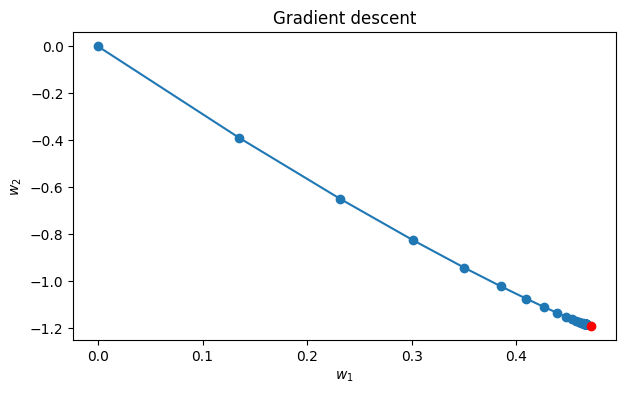

In [ ]:
# Визуализируем изменение весов (красной точкой обозначены истинные веса, сгенерированные вначале)
plt.figure(figsize=(7, 4))
plt.title('Gradient descent')
plt.xlabel(r'$w_1$')
plt.ylabel(r'$w_2$')

plt.scatter(w_list[:, 0], w_list[:, 1])
plt.scatter(w_true[0], w_true[1], c='r')
plt.plot(w_list[:, 0], w_list[:, 1])

plt.show()

После каждой итерации значения искомых весов приближаются к истинным, однако, не становятся им равны из-за шума, добавленного в вектор ответов.

Text(0, 0.5, 'MSE')

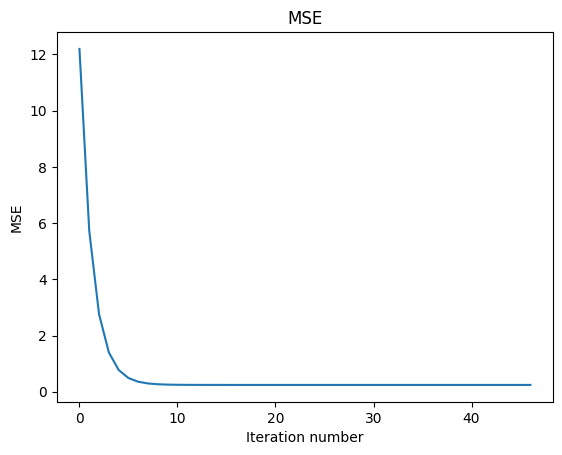

In [ ]:
# Визуализируем изменение функционала ошибки
plt.plot(range(len(errors)), errors)
plt.title('MSE')
plt.xlabel('Iteration number')
plt.ylabel('MSE')

Очень важно при использовании метода градиентного спуска правильно подбирать шаг. Если длина шага будет слишком мала, то метод будет слишком медленно приближаться к правильному ответу, и потребуется очень большое количество итераций для достижения сходимости. Если же длина наоборот будет слишком большой, появится вероятность "перепрыгивания" алгоритма через минимум функции или вообще отсутствия сходимости градиентного спуска.

Применяется методика использования переменного размера шага: на начальных этапах берется большой шаг, который с увеличением количества итераций снижается. Одна из таких методик - вычисление на каждой итерации размера шага по формуле

$$\eta_{k} = \frac{c}{k},$$

где $c$ - некоторая константа, а $k$ - номер шага.